# 01 — Data & Exploratory Data Analysis

Goal: get the verified Fashion-MNIST data with the fixed split, then explore the **training split only** to find out
which clothing classes will be hard to tell apart.

> **No-leakage rule:** EDA looks only at `X_train` / `y_train` (54k). The validation and test images are not looked at here,
> so nothing we learn from EDA can be influenced by the data we later evaluate on.

In [1]:
# Make `src` importable whether this notebook runs from notebooks/ or from the repo root
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from src import config
from src.data import download_raw, run_sanity_checks, load_splits
from src.utils import set_seed, save_fig, Timer

set_seed()
CLASS_NAMES = config.CLASS_NAMES

## 1. Download, verify and sanity-check the data
`download_raw()` checks each file against Zalando's published MD5. `run_sanity_checks()` verifies shapes, label range,
class balance and NaNs, and counts exact-duplicate images (by hashing each image) inside train, inside test, and across them.

In [2]:
download_raw()
report = run_sanity_checks()

all 4 raw files present and verified (MD5 OK)


train_shape                  [60000, 28, 28]
test_shape                   [10000, 28, 28]
image_dtype                  uint8
label_dtype                  int64
pixel_range                  [0, 255]
label_range                  [0, 9]
nan_count                    0
train_class_counts           [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]
test_class_counts            [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
duplicates_within_train      0
duplicates_within_test       0
test_images_also_in_train    0


## 2. Load the fixed split and keep only the training part
`load_splits()` reads the committed `data/splits/val_indices.npy` (6,000 stratified indices, seed 42) and returns
54k train / 6k val / 10k test as float32 in [0, 1]. For EDA we keep only the training arrays.

In [3]:
splits = load_splits()
print({k: v.shape for k, v in splits.items()})
X, y = splits["X_train"], splits["y_train"]
del splits  # val/test are not used anywhere in this notebook
print("train class counts:", np.bincount(y).tolist())

val_indices.npy MD5: 54ff6b78b27109cdfc3ebe7204040a07


{'X_train': (54000, 28, 28), 'y_train': (54000,), 'X_val': (6000, 28, 28), 'y_val': (6000,), 'X_test': (10000, 28, 28), 'y_test': (10000,)}
train class counts: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]


## 3. What do the images look like?

saved results/figures/eda_sample_grid.png


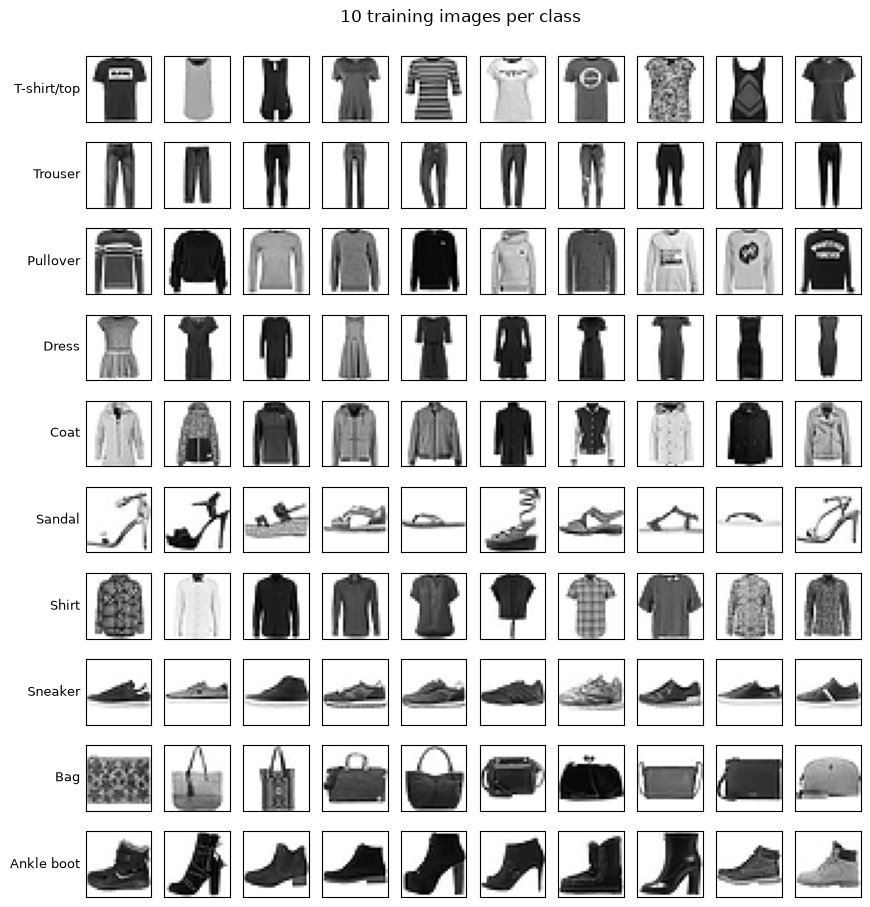

In [4]:
fig, axes = plt.subplots(10, 10, figsize=(10, 11))
for c in range(config.NUM_CLASSES):
    idx = np.where(y == c)[0][:10]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X[i], cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
    axes[c, 0].set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("10 training images per class", y=0.92)
save_fig(fig, "eda_sample_grid"); plt.show()

## 4. Mean and standard-deviation image per class
The **mean image** is the "average shape" of a class. The **std image** shows where pixels vary most between items of
that class. Classes with similar mean images will be hard for any model that looks at raw pixels.

saved results/figures/eda_class_mean_images.png


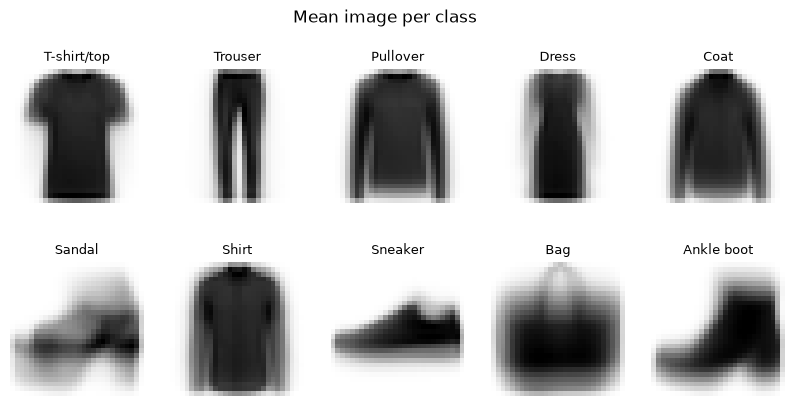

saved results/figures/eda_class_std_images.png


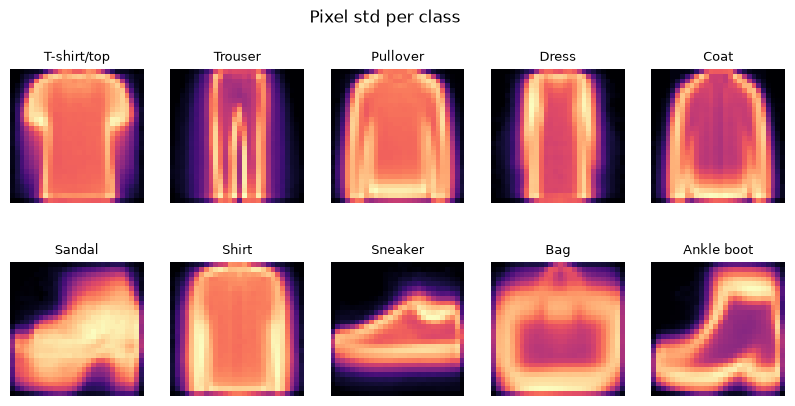

In [5]:
class_means = np.stack([X[y == c].mean(axis=0) for c in range(config.NUM_CLASSES)])
class_stds = np.stack([X[y == c].std(axis=0) for c in range(config.NUM_CLASSES)])

for name, imgs, title in [("eda_class_mean_images", class_means, "Mean image per class"),
                          ("eda_class_std_images", class_stds, "Pixel std per class")]:
    fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
    for c, ax in enumerate(axes.flat):
        ax.imshow(imgs[c], cmap="gray_r" if "mean" in name else "magma")
        ax.set_title(CLASS_NAMES[c], fontsize=9); ax.axis("off")
    fig.suptitle(title)
    save_fig(fig, name); plt.show()

## 5. Pixel intensities
Most pixels are background (0). The right plot shows how the average brightness ("ink") of an image differs by class.

saved results/figures/eda_pixel_intensity.png


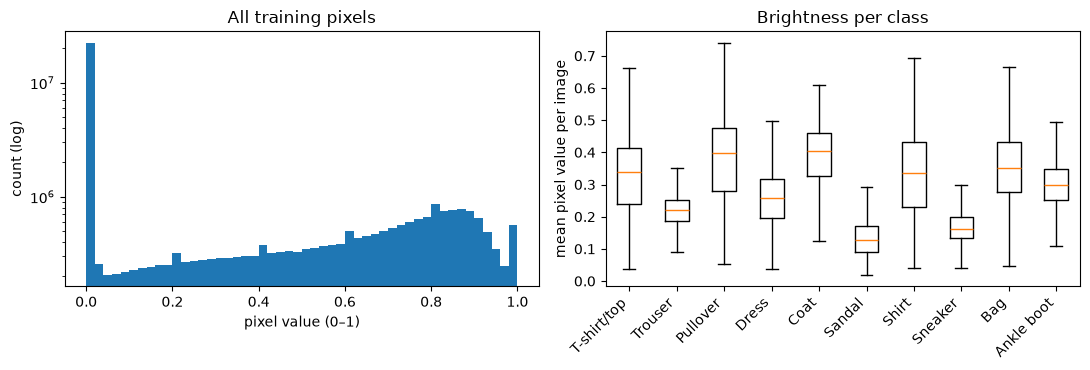

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(X.ravel(), bins=50, color="tab:blue")
axes[0].set_yscale("log"); axes[0].set_xlabel("pixel value (0–1)"); axes[0].set_ylabel("count (log)")
axes[0].set_title("All training pixels")

mean_ink = X.reshape(len(X), -1).mean(axis=1)
axes[1].boxplot([mean_ink[y == c] for c in range(config.NUM_CLASSES)], showfliers=False)
axes[1].set_xticks(range(1, 11), CLASS_NAMES, rotation=45, ha="right")
axes[1].set_ylabel("mean pixel value per image"); axes[1].set_title("Brightness per class")
fig.tight_layout()
save_fig(fig, "eda_pixel_intensity"); plt.show()

## 6. PCA: how much structure is in the 784 pixels?
PCA finds the directions of largest variance. The explained-variance curve tells phase 02 how many components keep
90% / 95% of the information. The 2-D projection shows which classes overlap linearly.

components for 90% variance: 84 | for 95%: 188 (out of 784)
saved results/figures/eda_pca_variance.png


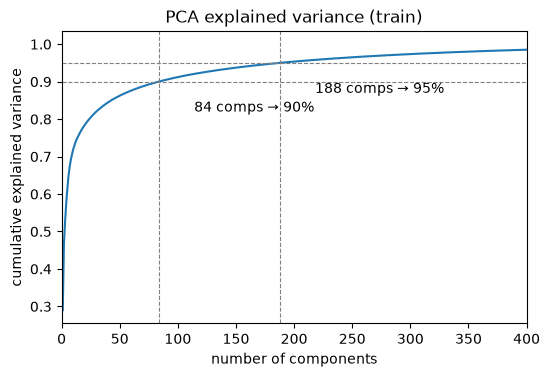

In [7]:
X_flat = X.reshape(len(X), -1)
pca_full = PCA(random_state=config.SEED).fit(X_flat)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)
print(f"components for 90% variance: {n90} | for 95%: {n95} (out of 784)")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(np.arange(1, 785), cum)
for n, lvl in [(n90, 0.90), (n95, 0.95)]:
    ax.axhline(lvl, ls="--", c="gray", lw=0.8); ax.axvline(n, ls="--", c="gray", lw=0.8)
    ax.annotate(f"{n} comps → {lvl:.0%}", (n, lvl), xytext=(n + 30, lvl - 0.08))
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance")
ax.set_xlim(0, 400); ax.set_title("PCA explained variance (train)")
save_fig(fig, "eda_pca_variance"); plt.show()

saved results/figures/eda_pca_2d.png


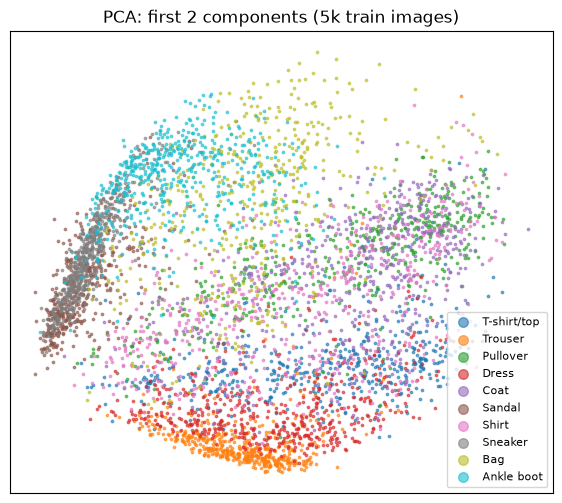

In [8]:
rng = np.random.default_rng(config.SEED)
sub = rng.choice(len(X), size=5000, replace=False)   # same 5k subsample for PCA-2D and t-SNE
Z = pca_full.transform(X_flat[sub])[:, :2]

def scatter_by_class(ax, Z2, labels, title):
    cmap = plt.get_cmap("tab10")
    for c in range(config.NUM_CLASSES):
        m = labels == c
        ax.scatter(Z2[m, 0], Z2[m, 1], s=3, color=cmap(c), label=CLASS_NAMES[c], alpha=0.6)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(figsize=(7, 6))
scatter_by_class(ax, Z, y[sub], "PCA: first 2 components (5k train images)")
ax.legend(markerscale=4, fontsize=8, loc="best")
save_fig(fig, "eda_pca_2d"); plt.show()

## 7. t-SNE: non-linear neighbourhoods
t-SNE places images that are close in pixel space close together on the map. Unlike PCA it isn't linear, so it shows
clusters better, but distances *between* clusters on the plot don't mean much. Standard practice: first reduce to 50 PCA components,
then run t-SNE (faster, less noise). ⏱ ~1 min.

t-SNE: 9.9s


saved results/figures/eda_tsne.png


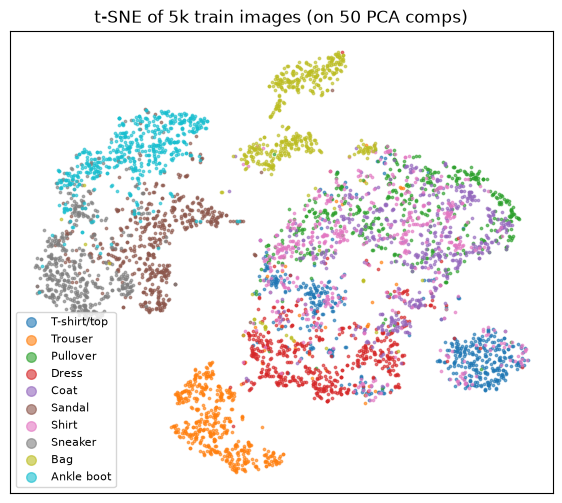

In [9]:
X50 = pca_full.transform(X_flat[sub])[:, :50]
with Timer("t-SNE"):
    T = TSNE(n_components=2, perplexity=30, init="pca", random_state=config.SEED).fit_transform(X50)

fig, ax = plt.subplots(figsize=(7, 6))
scatter_by_class(ax, T, y[sub], "t-SNE of 5k train images (on 50 PCA comps)")
ax.legend(markerscale=4, fontsize=8, loc="best")
save_fig(fig, "eda_tsne"); plt.show()

## 8. Which classes look alike? Similarity of class-mean images
Cosine similarity between the 10 mean images (1 = identical shape). This is a first, model-free guess at which pairs
will be confused.

saved results/figures/eda_class_similarity.png


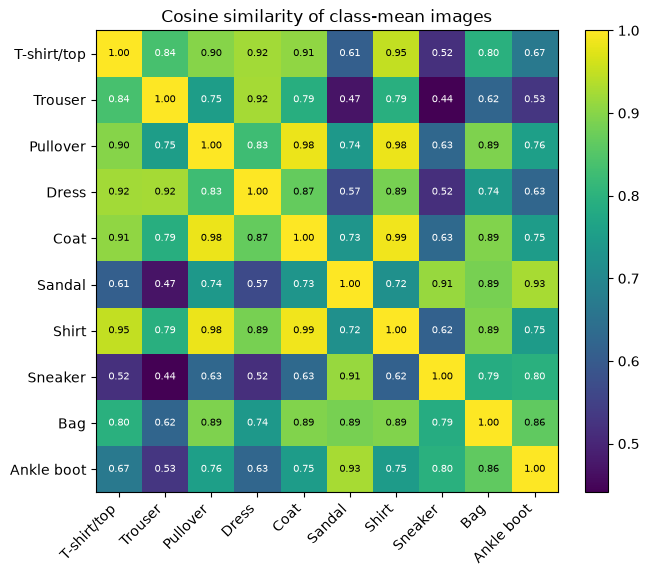

Most similar class pairs:
  0.987  Coat vs Shirt
  0.984  Pullover vs Coat
  0.983  Pullover vs Shirt
  0.950  T-shirt/top vs Shirt
  0.926  Sandal vs Ankle boot
  0.925  Trouser vs Dress
  0.923  T-shirt/top vs Dress
  0.915  Sandal vs Sneaker


In [10]:
M = class_means.reshape(config.NUM_CLASSES, -1)
M = M / np.linalg.norm(M, axis=1, keepdims=True)
sim = M @ M.T

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sim, cmap="viridis", vmin=sim.min(), vmax=1)
ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="black" if sim[i, j] > 0.85 else "white")
fig.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Cosine similarity of class-mean images")
save_fig(fig, "eda_class_similarity"); plt.show()

pairs = sorted(((sim[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(i + 1, 10)), reverse=True)
print("Most similar class pairs:")
for s, a, b in pairs[:8]:
    print(f"  {s:.3f}  {a} vs {b}")

## 9. Conclusion: expected hard classes

**Expected hard classes: Shirt, Coat, Pullover (and Shirt vs T-shirt/top).**

- **Upper-body garments overlap almost completely.** Their class-mean images are nearly identical (cosine similarity:
  Coat–Shirt 0.987, Pullover–Coat 0.984, Pullover–Shirt 0.983, T-shirt/top–Shirt 0.950), and in the t-SNE map Pullover,
  Coat and Shirt form **one mixed cloud** instead of three clusters. Shirt points also appear inside the T-shirt/top cluster.
  **Shirt overlaps with three other classes, so we expect it to have the lowest recall for every model.**
- **Why:** these garments share the same silhouette (torso + sleeves). What tells them apart (a collar, buttons, a zip,
  sleeve length, fabric texture) covers only a few pixels at 28×28, so models that compare whole-image pixels, or even
  coarse edge histograms (HOG), have little signal to separate them. This is the main question for phases 02–05
  and the motivation for a CNN in capstone Phase 2, which can learn small local patterns.
- **Footwear (Sandal, Sneaker, Ankle boot)** sits close together but forms separate sub-clusters, so we expect some confusion,
  mostly Sneaker ↔ Sandal and Sneaker ↔ Ankle boot.
- **Easy classes:** Trouser and Bag form clean, isolated clusters. Dress is mostly separate, with some overlap with T-shirt/top.
- **Redundancy:** 84 PCA components keep 90% of the pixel variance and 188 keep 95% (out of 784). Raw pixels are highly
  redundant, which is useful to know for the parked "PCA-reduced pixels" idea and for kNN/SVM speed.